In [1]:
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv('../data/sintetica/demanda_diaria.csv', parse_dates=["fecha"])

print(datos.shape)
datos.head()

(920, 11)


,fecha,producto_id,producto,dia_semana,feriado,evento,stock_inicial,unidades_solicitadas,unidades_vendidas,unidades_no_atendidas,agotado_desde
0,2026-05-01,P01,Ceviche clásico,4,1,NaN,38,37,37,0,NaN
1,2026-05-01,P02,Ceviche mixto,4,1,NaN,29,34,29,5,2026-05-01T19:14
2,2026-05-01,P03,Chicharrón de pescado,4,1,NaN,25,28,25,3,2026-05-01T20:39
3,2026-05-01,P04,Chicharrón de pota,4,1,NaN,36,17,17,0,NaN
4,2026-05-01,P05,Leche de tigre,4,1,NaN,28,19,19,0,NaN


In [2]:
print(datos["producto"].unique())
print(datos["fecha"].min(), "→", datos["fecha"].max())
datos[["unidades_solicitadas", "unidades_vendidas", "unidades_no_atendidas"]].describe()                   

<StringArray>
[      'Ceviche clásico',         'Ceviche mixto', 'Chicharrón de pescado',
    'Chicharrón de pota',        'Leche de tigre']
Length: 5, dtype: str
2026-05-01 00:00:00 → 2026-10-31 00:00:00


,unidades_solicitadas,unidades_vendidas,unidades_no_atendidas
count,920.000000,920.000000,920.000000
mean,26.523913,24.353261,2.170652
std,12.814126,9.649471,5.331473
min,5.000000,5.000000,0.000000
25%,17.000000,17.000000,0.000000
50%,23.000000,23.000000,0.000000
75%,34.000000,30.000000,0.000000
max,82.000000,50.000000,45.000000


In [3]:
agotados = datos[datos["unidades_no_atendidas"] > 0]
print(f"Días-plato agotados: {len(agotados)} de {len(datos)}")
print(f"Unidades no atendidas en total: {datos['unidades_no_atendidas'].sum()}")

Días-plato agotados: 221 de 920
Unidades no atendidas en total: 1997


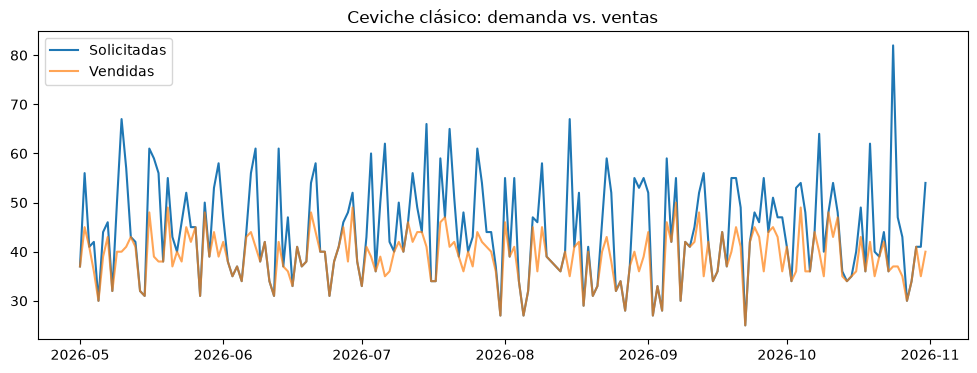

In [4]:
ceviche = datos[datos["producto"] == "Ceviche clásico"]

plt.figure(figsize=(12, 4))
plt.plot(ceviche["fecha"], ceviche["unidades_solicitadas"], label="Solicitadas")
plt.plot(ceviche["fecha"], ceviche["unidades_vendidas"], label="Vendidas", alpha=0.7)
plt.legend()
plt.title("Ceviche clásico: demanda vs. ventas")
plt.show()

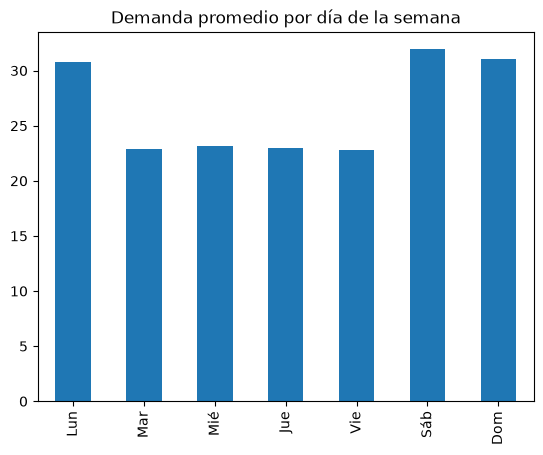

In [5]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia = datos.groupby("dia_semana")["unidades_solicitadas"].mean()
por_dia.index = dias
por_dia.plot(kind="bar", title="Demanda promedio por día de la semana")
plt.show()

In [6]:
df = datos.copy()

# Variables de calendario
df["hay_evento"] = df["evento"].notna().astype(int)          # vacío → 0, con evento → 1
df["producto_cod"] = df["producto_id"].str[1:].astype(int)   # "P01" → 1

# Variables de historia (solo mirando 7+ días atrás)
df = df.sort_values(["producto_id", "fecha"])
grupo = df.groupby("producto_id")["unidades_solicitadas"]
df["hace_7_dias"] = grupo.shift(7)
df["hace_14_dias"] = grupo.shift(14)
df["media_7_dias"] = grupo.transform(lambda s: s.shift(7).rolling(7).mean())

# Los primeros 14 días de cada plato no tienen historia suficiente
df = df.dropna(subset=["hace_14_dias", "media_7_dias"]).reset_index(drop=True)

print(df.shape)
df[["fecha", "producto", "dia_semana", "feriado", "hay_evento",
    "hace_7_dias", "media_7_dias", "unidades_solicitadas"]].head(10)

(850, 16)


,fecha,producto,dia_semana,feriado,hay_evento,hace_7_dias,media_7_dias,unidades_solicitadas
0,2026-05-15,Ceviche clásico,4,0,0,32.0,41.571429,31
1,2026-05-16,Ceviche clásico,5,0,0,50.0,40.714286,61
2,2026-05-17,Ceviche clásico,6,0,1,67.0,44.428571,59
3,2026-05-18,Ceviche clásico,0,0,0,57.0,46.571429,56
4,2026-05-19,Ceviche clásico,1,0,0,43.0,48.428571,38
5,2026-05-20,Ceviche clásico,2,0,0,42.0,48.142857,55
6,2026-05-21,Ceviche clásico,3,0,0,32.0,46.142857,43
7,2026-05-22,Ceviche clásico,4,0,0,31.0,46.000000,40
8,2026-05-23,Ceviche clásico,5,0,0,61.0,47.571429,46
9,2026-05-24,Ceviche clásico,6,0,0,59.0,46.428571,52


In [7]:
corte = df["fecha"].max() - pd.Timedelta(days=27)   # últimos 28 días = prueba

entreno = df[df["fecha"] < corte]
prueba = df[df["fecha"] >= corte]

print("Entrenamiento:", entreno["fecha"].min().date(), "→", entreno["fecha"].max().date(), "|", len(entreno), "filas")
print("Prueba:       ", prueba["fecha"].min().date(), "→", prueba["fecha"].max().date(), "|", len(prueba), "filas")
print("Eventos en prueba:", prueba["hay_evento"].sum() // 5, "| feriados en prueba:", prueba["feriado"].sum() // 5)

Entrenamiento: 2026-05-15 → 2026-10-03 | 710 filas
Prueba:        2026-10-04 → 2026-10-31 | 140 filas
Eventos en prueba: 1 | feriados en prueba: 1


In [8]:
promedios = (entreno
             .groupby(["producto_id", "dia_semana"])["unidades_solicitadas"]
             .mean()
             .rename("pred_base")
             .reset_index())

prueba = prueba.merge(promedios, on=["producto_id", "dia_semana"], how="left")
prueba[["fecha", "producto", "dia_semana", "unidades_solicitadas", "pred_base"]].head(10)

,fecha,producto,dia_semana,unidades_solicitadas,pred_base
0,2026-10-04,Ceviche clásico,6,54,51.450000
1,2026-10-05,Ceviche clásico,0,48,51.400000
2,2026-10-06,Ceviche clásico,1,36,38.600000
3,2026-10-07,Ceviche clásico,2,44,39.500000
4,2026-10-08,Ceviche clásico,3,64,39.250000
5,2026-10-09,Ceviche clásico,4,40,38.190476
6,2026-10-10,Ceviche clásico,5,48,52.000000
7,2026-10-11,Ceviche clásico,6,54,51.450000
8,2026-10-12,Ceviche clásico,0,48,51.400000
9,2026-10-13,Ceviche clásico,1,36,38.600000


In [9]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluar(nombre, real, predicho):
    return {
        "modelo": nombre,
        "MAE": round(mean_absolute_error(real, predicho), 2),
        "RMSE": round(np.sqrt(mean_squared_error(real, predicho)), 2),
        "MAPE %": round(mean_absolute_percentage_error(real, predicho) * 100, 1),
    }

resultados = [evaluar("Promedio por día (base)", prueba["unidades_solicitadas"], prueba["pred_base"])]
pd.DataFrame(resultados)

,modelo,MAE,RMSE,MAPE %
0,Promedio por día (base),4.67,6.77,19.6


In [10]:
prueba[prueba["hay_evento"] == 1][["fecha", "producto", "unidades_solicitadas", "pred_base"]]

,fecha,producto,unidades_solicitadas,pred_base
20,2026-10-24,Ceviche clásico,82,52.000000
48,2026-10-24,Ceviche mixto,65,37.476190
76,2026-10-24,Chicharrón de pescado,52,26.000000
104,2026-10-24,Chicharrón de pota,26,19.904762
132,2026-10-24,Leche de tigre,23,21.857143


In [11]:
from sklearn.ensemble import RandomForestRegressor

pistas = ["producto_cod", "dia_semana", "feriado", "hay_evento",
          "hace_7_dias", "hace_14_dias", "media_7_dias"]

bosque = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)
bosque.fit(entreno[pistas], entreno["unidades_solicitadas"])     # aprende del cuaderno
prueba["pred_bosque"] = bosque.predict(prueba[pistas])            # adivina octubre

resultados.append(evaluar("Random Forest (todas las pistas)", prueba["unidades_solicitadas"], prueba["pred_bosque"]))
pd.DataFrame(resultados)

,modelo,MAE,RMSE,MAPE %
0,Promedio por día (base),4.67,6.77,19.6
1,Random Forest (todas las pistas),4.97,6.92,21.0


In [12]:
pistas_calendario = ["producto_cod", "dia_semana", "feriado", "hay_evento"]

bosque2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)
bosque2.fit(entreno[pistas_calendario], entreno["unidades_solicitadas"])
prueba["pred_bosque2"] = bosque2.predict(prueba[pistas_calendario])

resultados.append(evaluar("Random Forest (solo calendario)", prueba["unidades_solicitadas"], prueba["pred_bosque2"]))
pd.DataFrame(resultados)

,modelo,MAE,RMSE,MAPE %
0,Promedio por día (base),4.67,6.77,19.6
1,Random Forest (todas las pistas),4.97,6.92,21.0
2,Random Forest (solo calendario),4.63,6.71,19.5


In [13]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
xgb.fit(entreno[pistas_calendario], entreno["unidades_solicitadas"])
prueba["pred_xgb"] = xgb.predict(prueba[pistas_calendario])

resultados.append(evaluar("XGBoost (solo calendario)", prueba["unidades_solicitadas"], prueba["pred_xgb"]))
pd.DataFrame(resultados)

,modelo,MAE,RMSE,MAPE %
0,Promedio por día (base),4.67,6.77,19.6
1,Random Forest (todas las pistas),4.97,6.92,21.0
2,Random Forest (solo calendario),4.63,6.71,19.5
3,XGBoost (solo calendario),4.26,5.51,18.9


In [14]:
prueba[prueba["fecha"] == "2026-10-24"][["producto", "unidades_solicitadas", "pred_base", "pred_bosque2", "pred_xgb"]].round(0)

,producto,unidades_solicitadas,pred_base,pred_bosque2,pred_xgb
20,Ceviche clásico,82,52.0,52.0,65.0
48,Ceviche mixto,65,37.0,37.0,50.0
76,Chicharrón de pescado,52,26.0,27.0,49.0
104,Chicharrón de pota,26,20.0,22.0,28.0
132,Leche de tigre,23,22.0,24.0,26.0


In [15]:
import logging
from prophet import Prophet
logging.getLogger("cmdstanpy").disabled = True        # silencia mensajes técnicos

predicciones = []
for plato in entreno["producto_id"].unique():         # repite para P01, P02 ... P05
    historia = entreno[entreno["producto_id"] == plato].rename(columns={"fecha": "ds", "unidades_solicitadas": "y"})
    futuro = prueba[prueba["producto_id"] == plato].rename(columns={"fecha": "ds"})

    modelo = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False)
    modelo.add_regressor("feriado")                     # pista extra: ¿es feriado?
    modelo.add_regressor("hay_evento")                  # pista extra: ¿hay evento?
    modelo.fit(historia[["ds", "y", "feriado", "hay_evento"]])

    resultado = modelo.predict(futuro[["ds", "feriado", "hay_evento"]])
    predicciones.append(pd.Series(resultado["yhat"].values, index=futuro.index))

prueba["pred_prophet"] = pd.concat(predicciones)

resultados.append(evaluar("Prophet (con feriado y evento)", prueba["unidades_solicitadas"], prueba["pred_prophet"]))
pd.DataFrame(resultados)

Importing plotly failed. Interactive plots will not work.


,modelo,MAE,RMSE,MAPE %
0,Promedio por día (base),4.67,6.77,19.6
1,Random Forest (todas las pistas),4.97,6.92,21.0
2,Random Forest (solo calendario),4.63,6.71,19.5
3,XGBoost (solo calendario),4.26,5.51,18.9
4,Prophet (con feriado y evento),4.41,5.66,19.6


In [16]:
resultados = pd.DataFrame(resultados).drop_duplicates("modelo").to_dict("records")
tabla = pd.DataFrame(resultados).sort_values("MAE").reset_index(drop=True)
tabla

,modelo,MAE,RMSE,MAPE %
0,XGBoost (solo calendario),4.26,5.51,18.9
1,Prophet (con feriado y evento),4.41,5.66,19.6
2,Random Forest (solo calendario),4.63,6.71,19.5
3,Promedio por día (base),4.67,6.77,19.6
4,Random Forest (todas las pistas),4.97,6.92,21.0


Modelo elegido: XGBoost. En promedio falla por 4.26 platos, el menor error de los 5 modelos y un 9% menos que el promedio por día de la semana (4.67). También tiene el RMSE más bajo (5.51), es decir, es el que menos se equivoca en los días difíciles, como feriados y eventos.

Limitaciones: los datos son simulados, así que con datos reales del restaurante habría que volver a entrenar y comparar. Además, con solo 2 eventos en el historial, el modelo se queda corto esos días; por eso, en un día de evento conviene preparar un poco más de lo predicho.

In [17]:
todo = datos.copy()
todo["hay_evento"] = todo["evento"].notna().astype(int)
todo["producto_cod"] = todo["producto_id"].str[1:].astype(int)

modelo_final = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
modelo_final.fit(todo[pistas_calendario], todo["unidades_solicitadas"])

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [18]:
platos = todo[["producto_id", "producto", "producto_cod"]].drop_duplicates()
semana = pd.DataFrame({"fecha": pd.date_range("2026-11-01", periods=7)})

futuro = platos.merge(semana, how="cross")          # 5 platos × 7 días = 35 filas
futuro["dia_semana"] = futuro["fecha"].dt.day_of_week
futuro["feriado"] = (futuro["fecha"] == "2026-11-01").astype(int)   # Todos los Santos
futuro["hay_evento"] = 0

futuro["cantidad_prevista"] = modelo_final.predict(futuro[pistas_calendario]).round().astype(int)

futuro["dia"] = futuro["fecha"].dt.strftime("%d/%m")
futuro.pivot(index="producto", columns="dia", values="cantidad_prevista")

dia,01/11,02/11,03/11,04/11,05/11,06/11,07/11
producto,,,,,,,
Ceviche clásico,51,51,38,39,39,39,51
Ceviche mixto,41,36,26,26,26,27,36
Chicharrón de pescado,28,26,20,20,19,20,26
Chicharrón de pota,21,18,13,14,14,13,19
Leche de tigre,23,22,17,16,16,15,21


In [19]:
salida = futuro[["fecha", "producto_id", "producto", "cantidad_prevista"]].copy()
salida["fecha"] = salida["fecha"].dt.strftime("%Y-%m-%d")
salida["modelo"] = "xgboost-calendario-v1"
salida = salida.sort_values(["fecha", "producto_id"])

salida.to_csv("prediccion_7_dias.csv", index=False, encoding="utf-8")
print(len(salida), "filas guardadas")
salida.head()

35 filas guardadas


,fecha,producto_id,producto,cantidad_prevista,modelo
0,2026-11-01,P01,Ceviche clásico,51,xgboost-calendario-v1
7,2026-11-01,P02,Ceviche mixto,41,xgboost-calendario-v1
14,2026-11-01,P03,Chicharrón de pescado,28,xgboost-calendario-v1
21,2026-11-01,P04,Chicharrón de pota,21,xgboost-calendario-v1
28,2026-11-01,P05,Leche de tigre,23,xgboost-calendario-v1
